# 🏭 Lab 04b: Production-Grade RAG System

## Supplemental Lab after Module 04 — Building and Evaluating a Real-World RAG Pipeline 🧪

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04b-production-rag-lab.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 45–60 min hands-on |
| 🎚️ **Level** | Intermediate–advanced: you build the pipeline yourself |
| 🔑 **Accounts / keys** | None required. Optional `OPENAI_API_KEY` for real generation |
| 🧰 **You'll use** | `weaviate-client` v4 (embedded) · `sentence-transformers` · `pandas` · optional `openai` |
| 🔗 **Depends on Lab 04?** | No code dependency. Concepts (Recall@K, Precision@K, nDCG, faithfulness) are re-explained in the **📏 Metrics primer** below, so you can do this lab on its own |
| 🏁 **You'll leave with** | A working vector-DB RAG pipeline, a chunking comparison, and a readiness verdict |


---

## 🧭 Overview

In this lab, you will build a **production-grade Retrieval-Augmented Generation (RAG) system** from scratch. Unlike toy examples, this lab reflects how enterprise teams actually build, evaluate, and monitor RAG systems in production.

### 🏗️ What You'll Build

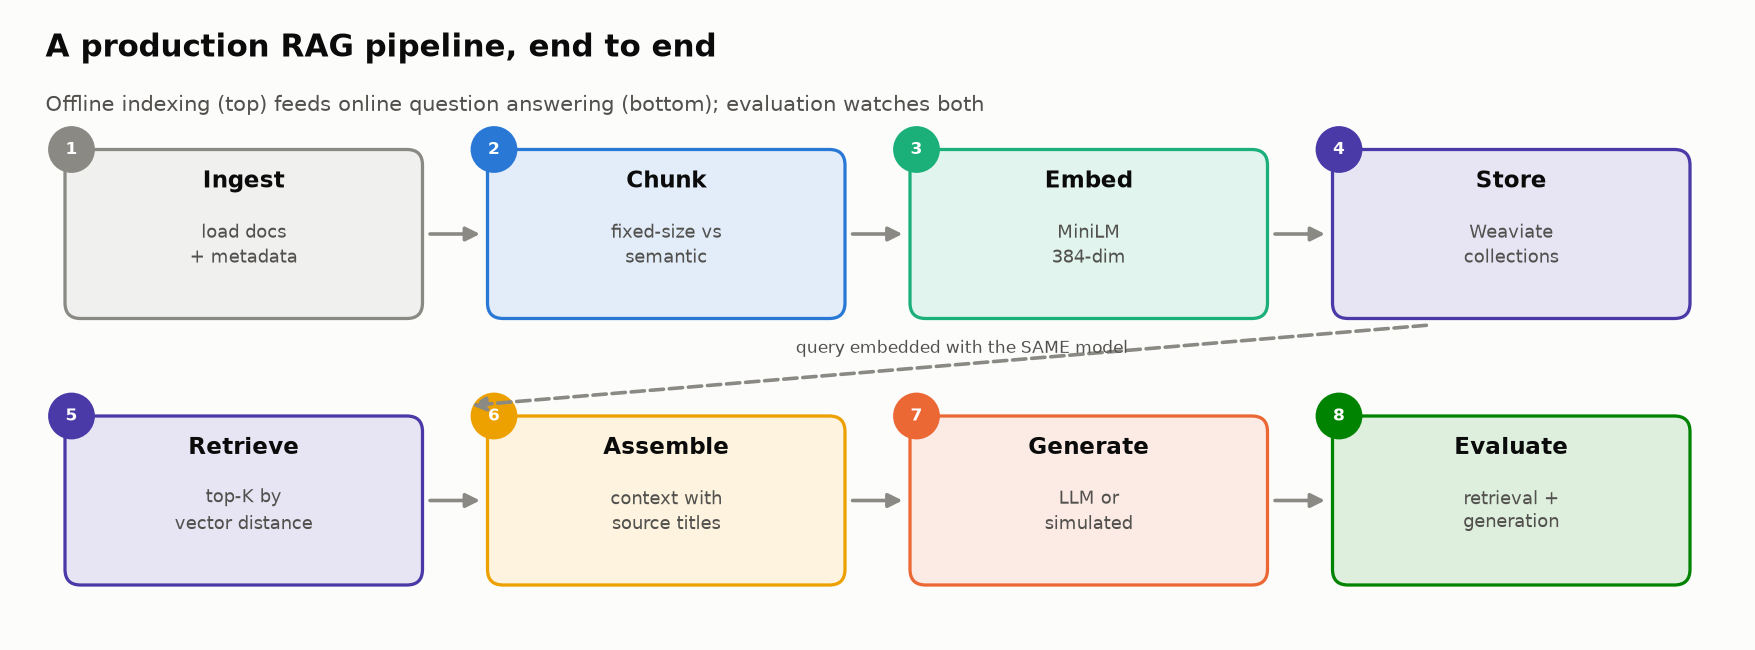

<sub>🖼️ *The eight stages you'll build: offline indexing on top, online answering below*</sub>

By the end of this lab you will have:
- ✅ Built a complete RAG pipeline with Weaviate (embedded, v4 client) as the vector database
- ✅ Implemented and compared multiple chunking strategies
- ✅ Measured retrieval quality with Recall@K, Precision@K, and nDCG
- ✅ Evaluated generation quality with simplified, RAGAS-style Faithfulness and Answer Relevancy metrics
- ✅ Made data-driven decisions about chunking and retrieval strategies

---

## 🎯 Learning Objectives

1. Build a modular RAG pipeline following production best practices
2. Implement and compare chunking strategies (fixed-size vs. semantic)
3. Store and retrieve embeddings from a vector database (Weaviate)
4. Evaluate retrieval quality with standard metrics (Recall@K, Precision@K, nDCG)
5. Evaluate generation quality with RAGAS-style metrics (Faithfulness, Answer Relevancy) and explain how the full RAGAS library differs
6. Make a production-readiness decision based on evaluation results

---

## 📋 Prerequisites

- Module 01 (traces) recommended. Lab 04 is helpful but **not required**: the metrics are re-taught below
- Basic Python proficiency
- Understanding of embeddings and vector similarity

---

## ⏱️ Estimated Time

**45-60 minutes** hands-on

---

## 🎬 Scenario

You are an ML engineer at a company building a **technical documentation assistant**. Users ask questions about your product, and the system retrieves relevant documentation chunks and generates answers.

Management has asked you to:
1. Build the RAG pipeline with proper evaluation
2. Compare different chunking strategies to find the best one
3. Set up monitoring so you can catch problems in production
4. Make a recommendation on the best configuration to deploy

> ⚠️ **Key Insight:** The difference between a demo RAG system and a production RAG system is **evaluation and monitoring**. Without them, you're flying blind.

---

## 📏 Metrics primer (read this if you skipped Lab 04)

Everything you measure in this lab falls into two families. **Evaluate them separately**: a great retriever can't save a bad generator, and vice versa.

**🔍 Retrieval: did we fetch the right evidence?** Let *R* = the set of documents labelled relevant for a question, and *top-K* = the K chunks we retrieved (mapped back to their source `doc_id`).

| Metric | Formula | Question it answers | Example (K = 5, 1 relevant doc found at rank 2) |
|---|---|---|---|
| **Recall@K** | \|top-K ∩ R\| / \|R\| | Did we find **all** the evidence? | 1 / 1 = **1.00** |
| **Precision@K** | \|top-K ∩ R\| / K | How much of what we fetched is **noise**? | 1 / 5 = **0.20** |
| **nDCG@K** | DCG / ideal DCG, with DCG = Σ rel / log₂(rank + 1) | Is the evidence **near the top**? | (1/log₂3) / (1/log₂2) = **0.63** |

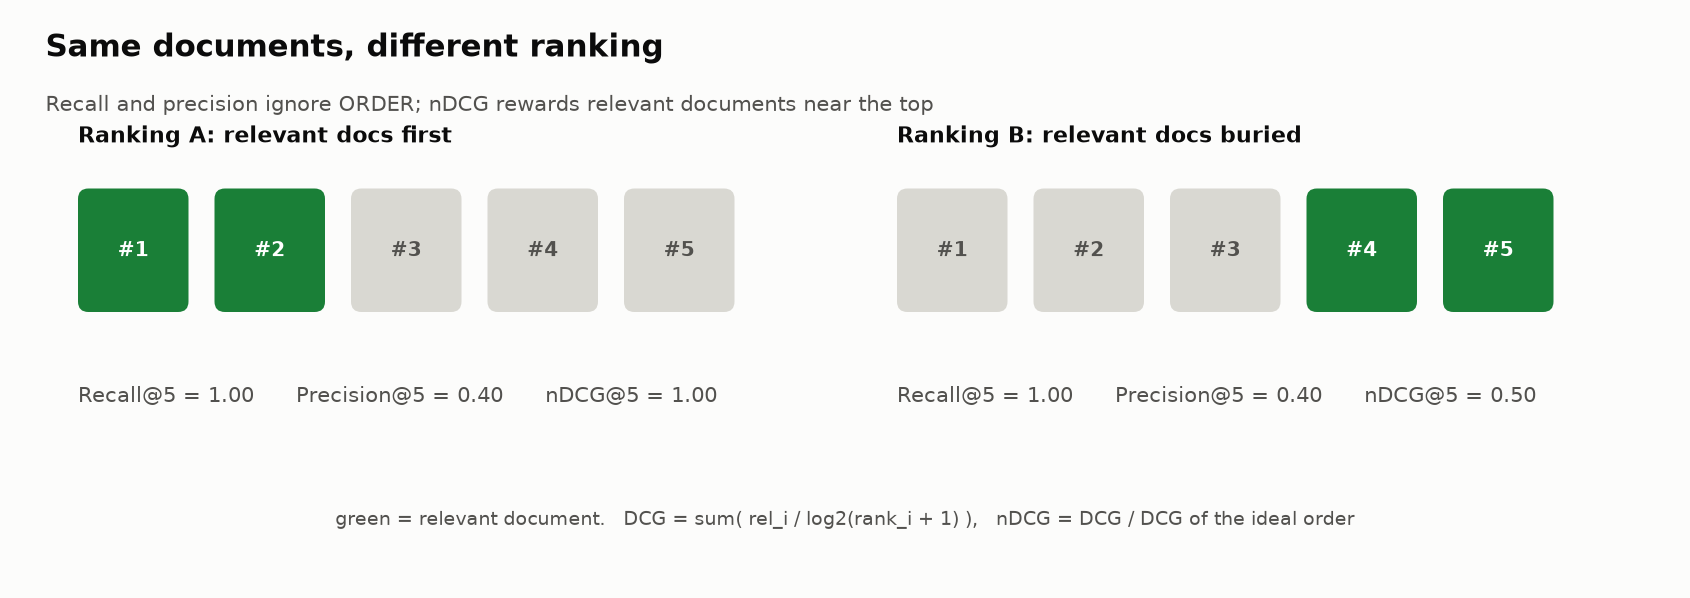

<sub>🖼️ *Recall and precision ignore order; nDCG rewards putting relevant evidence first*</sub>

**✍️ Generation: did the answer use the evidence well?**
- **Faithfulness**: are the answer's claims supported by the retrieved context? (Low = hallucination.)
- **Answer relevancy**: does the answer address the question that was asked?

> 💡 **RAGAS vs. this lab.** The RAGAS library computes these with an LLM judge (it extracts claims and checks each against the context). Here you'll build **lightweight, word-overlap versions** so the lab runs free and offline. They're great for learning the pipeline and terrible at catching subtle distortions (Lab 04 shows why). Swap in RAGAS or an NLI model for production.


---

## 🔧 Task 1: Environment Setup

### Goal
Install and configure all required packages for a production-grade RAG system.

### What We're Installing

| Package | Purpose | Why It Matters |
|---------|---------|----------------|
| `weaviate-client` (v4) | Vector database SDK, incl. **embedded** Weaviate | Production-grade vector storage with no server to manage |
| `sentence-transformers` | Local embedding model (`all-MiniLM-L6-v2`) | Free, offline embeddings |
| `openai` | Optional real LLM for generation | Only used if you set `OPENAI_API_KEY` |
| `pandas` / `numpy` | Tables and math | Metric reports |

> ℹ️ Earlier versions of this lab also installed `langchain`, `ragas` and `langfuse` but never used them. They're gone, which makes the install about 2× faster.

### Steps
Run the cells below to install packages and configure the environment.

In [ ]:
%%capture
# ============================================================
# INSTALL REQUIRED PACKAGES
# ============================================================
# %%capture hides the verbose pip output to keep the notebook clean.
#
# - weaviate-client>=4.9 : Weaviate's v4 Python SDK (includes embedded mode)
# - sentence-transformers: local embedding model (no API key needed)
# - openai               : OPTIONAL, only used if you provide an OPENAI_API_KEY
#
# Installation takes ~1 minute on Google Colab.

!pip install -q "weaviate-client>=4.9,<5" sentence-transformers openai pandas numpy

In [ ]:
# ============================================================
# IMPORTS AND CONFIGURATION
# ============================================================
# We organize imports by category for clarity.

# --- Standard library ---
import os
import json
import re
from typing import List, Dict, Any, Optional
from dataclasses import dataclass

# --- Data manipulation ---
import numpy as np
import pandas as pd

# --- Vector database (Weaviate v4 client) ---
import weaviate

# --- Embeddings ---
from sentence_transformers import SentenceTransformer

print("✅ All imports successful!")
print(f"   Weaviate client version: {weaviate.__version__}")
if not weaviate.__version__.startswith("4."):
    print("⚠️  This lab targets weaviate-client v4. Re-run the install cell, then Runtime → Restart session.")

In [ ]:
# ============================================================
# API KEYS SETUP
# ============================================================
# For this lab, you can use:
# 1. OpenAI API key (for embeddings + generation) - RECOMMENDED
# 2. No API keys (uses local sentence-transformers + simulated responses)
#
# If running in Google Colab, use the Secrets feature (key icon) to add:
# - OPENAI_API_KEY
# - LANGFUSE_PUBLIC_KEY (optional)
# - LANGFUSE_SECRET_KEY (optional)

# Try to get OpenAI key from environment or Colab secrets
OPENAI_API_KEY = os.environ.get("OPENAI_API_KEY", "")

# Check if running in Colab and try to get from secrets
try:
    from google.colab import userdata
    OPENAI_API_KEY = userdata.get('OPENAI_API_KEY') or OPENAI_API_KEY
except:
    pass

USE_OPENAI = bool(OPENAI_API_KEY)

if USE_OPENAI:
    print("✅ OpenAI API key found - will use OpenAI for embeddings and generation")
    os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY
else:
    print("⚠️ No OpenAI API key found - will use local models and simulated responses")
    print("   (This is fine for learning! The evaluation pipeline is the same.)")

### Checkpoint ✅
You should see import success messages above. If you see errors:
- `ModuleNotFoundError`: Re-run the pip install cell
- Version warnings: These are usually safe to ignore

---

## 📂 Task 2: Create Sample Document Corpus

### Goal
Create a realistic document corpus for our RAG system. We'll use technical documentation about a fictional product called "DataFlow" — a data pipeline tool.

### Why This Matters
In production, your documents come from various sources (APIs, databases, file systems). Here we simulate that with a representative sample that includes:
- Different document lengths
- Technical content with code examples
- Cross-referenced concepts
- Edge cases (short docs, long docs, code-heavy docs)

In [ ]:
# ============================================================
# SAMPLE DOCUMENT CORPUS
# ============================================================
# This simulates a technical documentation dataset.
# Each document has:
# - id: Unique identifier
# - title: Document title (used in chunking)
# - content: Full text content
# - category: Document category (for metadata filtering)
#
# In production, you'd load from:
# - S3/GCS buckets
# - Document databases
# - Web scrapers
# - CMS APIs

DOCUMENTS = [
    {
        "id": "doc-001",
        "title": "Getting Started with DataFlow",
        "category": "quickstart",
        "content": """
# Getting Started with DataFlow

DataFlow is a modern data pipeline orchestration platform that helps you build, deploy, and monitor data workflows at scale.

## Installation

Install DataFlow using pip:

```bash
pip install dataflow-sdk
```

## Quick Start

Create your first pipeline in 3 steps:

1. **Define your pipeline** using Python decorators
2. **Configure sources and sinks** in YAML
3. **Deploy to DataFlow Cloud** with one command

Example pipeline:

```python
from dataflow import Pipeline, task

@task
def extract_data():
    return fetch_from_api()

@task
def transform_data(raw_data):
    return clean_and_validate(raw_data)

@task  
def load_data(clean_data):
    write_to_database(clean_data)

pipeline = Pipeline([extract_data, transform_data, load_data])
```

## Key Concepts

- **Pipeline**: A directed acyclic graph (DAG) of tasks
- **Task**: A single unit of work (Python function)
- **Trigger**: What starts a pipeline (schedule, event, API call)
- **Run**: A single execution of a pipeline

## Next Steps

- Read the Configuration Guide for advanced options
- Check out the Monitoring Guide to track your pipelines
- Join our Slack community for help
"""
    },
    {
        "id": "doc-002", 
        "title": "DataFlow Configuration Guide",
        "category": "configuration",
        "content": """
# Configuration Guide

DataFlow uses YAML configuration files to define pipeline settings, connections, and deployment options.

## Configuration File Location

DataFlow looks for configuration in this order:
1. `./dataflow.yaml` (current directory)
2. `~/.dataflow/config.yaml` (user home)
3. `/etc/dataflow/config.yaml` (system-wide)

## Basic Configuration

```yaml
# dataflow.yaml
version: "2.0"

project:
  name: my-data-pipeline
  environment: production

connections:
  postgres:
    type: postgresql
    host: ${POSTGRES_HOST}
    port: 5432
    database: analytics
    credentials:
      secret: postgres-credentials

  s3:
    type: s3
    bucket: my-data-bucket
    region: us-west-2
```

## Environment Variables

Use `${VAR_NAME}` syntax to reference environment variables. This is the recommended way to handle secrets.

## Connection Types

DataFlow supports these connection types:
- **postgresql**: PostgreSQL databases
- **mysql**: MySQL databases
- **s3**: Amazon S3 buckets
- **gcs**: Google Cloud Storage
- **kafka**: Apache Kafka topics
- **http**: REST APIs

## Pipeline-Specific Configuration

Each pipeline can override global settings:

```yaml
pipelines:
  daily-etl:
    schedule: "0 6 * * *"  # 6 AM daily
    timeout: 3600  # 1 hour
    retries: 3
    notifications:
      on_failure: slack-alerts
```

## Secrets Management

Never put secrets directly in config files. Use:
1. Environment variables
2. DataFlow Secrets Manager
3. External secret managers (Vault, AWS Secrets Manager)
"""
    },
    {
        "id": "doc-003",
        "title": "DataFlow Monitoring and Observability",
        "category": "monitoring",
        "content": """
# Monitoring and Observability

DataFlow provides comprehensive monitoring capabilities to help you track pipeline health, debug issues, and optimize performance.

## Built-in Metrics

Every pipeline automatically tracks:
- **Run duration**: How long each run takes
- **Success/failure rate**: Percentage of successful runs
- **Task latency**: Time spent in each task
- **Data volume**: Rows processed, bytes transferred
- **Resource usage**: CPU, memory, network

## Dashboard

Access the monitoring dashboard at `https://app.dataflow.io/monitoring` or run locally:

```bash
dataflow dashboard
```

## Alerts

Configure alerts for pipeline issues:

```yaml
alerts:
  pipeline-failure:
    condition: run.status == "failed"
    channels: [slack, pagerduty]
    
  slow-pipeline:
    condition: run.duration > 2 * run.average_duration
    channels: [slack]
    
  data-quality:
    condition: metrics.null_rate > 0.05
    channels: [email]
```

## Logging

Logs are structured JSON by default. Configure log levels per task:

```python
@task(log_level="DEBUG")
def my_task():
    logger.info("Processing started", extra={"batch_id": 123})
```

## Integration with External Tools

DataFlow integrates with:
- **Prometheus**: Metrics export
- **Grafana**: Dashboard templates
- **Datadog**: Full APM integration
- **PagerDuty**: Incident routing
- **Slack**: Notifications

## Debugging Failed Runs

When a run fails:
1. Check the run logs in the dashboard
2. Look at the failed task's stack trace
3. Review input data for that task
4. Use `dataflow run --rerun-failed` to retry just failed tasks
"""
    },
    {
        "id": "doc-004",
        "title": "DataFlow Error Handling",
        "category": "troubleshooting",
        "content": """
# Error Handling

DataFlow provides robust error handling to ensure reliable pipeline execution.

## Retry Configuration

Configure retries at the task level:

```python
@task(retries=3, retry_delay=60)  # Retry 3 times, wait 60s between
def flaky_api_call():
    return requests.get(api_url).json()
```

Or at the pipeline level in YAML:

```yaml
pipelines:
  my-pipeline:
    retries: 3
    retry_delay: 60
    retry_backoff: exponential  # 60s, 120s, 240s
```

## Error Types

DataFlow distinguishes between:
- **Transient errors**: Network timeouts, rate limits (auto-retry)
- **Data errors**: Invalid input data (requires fix)
- **Code errors**: Bugs in task code (requires code change)

## Dead Letter Queues

For streaming pipelines, configure DLQ to capture failed messages:

```yaml
pipelines:
  streaming-etl:
    dead_letter_queue:
      type: kafka
      topic: failed-messages
      retention: 7d
```

## Circuit Breakers

Prevent cascading failures with circuit breakers:

```python
@task(circuit_breaker={"failures": 5, "timeout": 300})
def external_api_task():
    # If this fails 5 times in 5 minutes, circuit opens
    return call_external_api()
```

## Handling Partial Failures

For batch processing, handle partial failures:

```python
@task(on_partial_failure="continue")  # Don't fail entire batch
def process_batch(records):
    results = []
    for record in records:
        try:
            results.append(process(record))
        except Exception as e:
            logger.error(f"Failed to process {record.id}", exc_info=e)
            results.append(ErrorRecord(record.id, str(e)))
    return results
```
"""
    },
    {
        "id": "doc-005",
        "title": "DataFlow Security Best Practices",
        "category": "security",
        "content": """
# Security Best Practices

Follow these guidelines to secure your DataFlow deployments.

## Authentication

DataFlow supports multiple authentication methods:
- **API Keys**: For programmatic access
- **OAuth 2.0**: For user authentication
- **SAML**: For enterprise SSO

Never hardcode credentials. Use:

```python
# Bad - hardcoded credentials
conn = connect(password="secret123")

# Good - environment variable
conn = connect(password=os.environ["DB_PASSWORD"])

# Better - secrets manager
conn = connect(password=secrets.get("db-password"))
```

## Network Security

- Use VPC peering for database connections
- Enable TLS for all external connections
- Use private endpoints where available

## Data Encryption

DataFlow encrypts data:
- **At rest**: AES-256 encryption
- **In transit**: TLS 1.3
- **In memory**: Secure memory handling

For sensitive data, enable column-level encryption:

```yaml
pipelines:
  pii-pipeline:
    encryption:
      columns: [ssn, credit_card, email]
      algorithm: AES-256-GCM
      key_id: pii-encryption-key
```

## Access Control

Use role-based access control (RBAC):

```yaml
roles:
  developer:
    - pipelines:read
    - pipelines:write
    - runs:read
    
  operator:
    - pipelines:read
    - runs:read
    - runs:trigger
    
  admin:
    - "*:*"
```

## Audit Logging

All actions are logged for compliance:
- Who did what
- When it happened  
- What data was accessed
- What changed
"""
    },
    {
        "id": "doc-006",
        "title": "DataFlow Performance Optimization",
        "category": "performance",
        "content": """
# Performance Optimization

Optimize your DataFlow pipelines for speed and efficiency.

## Parallelization

Run independent tasks in parallel:

```python
# These run in parallel automatically
@task
def extract_users():
    return fetch_users()

@task
def extract_orders():
    return fetch_orders()

@task
def join_data(users, orders):  # Waits for both
    return merge(users, orders)
```

## Batch Processing

Process data in batches to reduce overhead:

```python
@task(batch_size=1000)
def process_records(records):
    # Process 1000 records at a time
    return bulk_insert(records)
```

## Caching

Cache expensive computations:

```python
@task(cache_key="{date}", cache_ttl=3600)
def fetch_daily_data(date):
    # Cached for 1 hour per date
    return expensive_api_call(date)
```

## Resource Allocation

Allocate resources based on task needs:

```yaml
tasks:
  heavy-computation:
    resources:
      cpu: 4
      memory: 16GB
      gpu: 1
      
  light-task:
    resources:
      cpu: 0.5
      memory: 512MB
```

## Common Bottlenecks

1. **Database connections**: Use connection pooling
2. **API rate limits**: Implement backoff strategies
3. **Memory pressure**: Stream large datasets
4. **Network latency**: Co-locate with data sources
"""
    }
]

print(f"✅ Created {len(DOCUMENTS)} documents for the RAG corpus")
print(f"   Categories: {set(d['category'] for d in DOCUMENTS)}")
print(f"   Total content: {sum(len(d['content']) for d in DOCUMENTS):,} characters")

In [ ]:
# ============================================================
# CREATE EVALUATION DATASET WITH GROUND TRUTH
# ============================================================
# For meaningful evaluation, we need:
# 1. Questions users might ask
# 2. Ground truth answers (or relevant document IDs)
# 3. Expected retrieved documents
#
# In production, this comes from:
# - User query logs
# - Support tickets
# - Manual annotation

EVALUATION_DATASET = [
    {
        "question": "How do I install DataFlow?",
        "ground_truth_answer": "Install DataFlow using pip: pip install dataflow-sdk",
        "relevant_doc_ids": ["doc-001"],
        "category": "installation"
    },
    {
        "question": "Where does DataFlow look for configuration files?",
        "ground_truth_answer": "DataFlow looks for config in this order: ./dataflow.yaml, ~/.dataflow/config.yaml, /etc/dataflow/config.yaml",
        "relevant_doc_ids": ["doc-002"],
        "category": "configuration"
    },
    {
        "question": "How can I monitor my pipeline's performance?",
        "ground_truth_answer": "DataFlow tracks run duration, success/failure rate, task latency, data volume, and resource usage. Access the dashboard at app.dataflow.io/monitoring",
        "relevant_doc_ids": ["doc-003"],
        "category": "monitoring"
    },
    {
        "question": "How do I configure retries for failed tasks?",
        "ground_truth_answer": "Configure retries at task level with @task(retries=3, retry_delay=60) or pipeline level in YAML",
        "relevant_doc_ids": ["doc-004"],
        "category": "troubleshooting"
    },
    {
        "question": "What authentication methods does DataFlow support?",
        "ground_truth_answer": "DataFlow supports API Keys, OAuth 2.0, and SAML for enterprise SSO",
        "relevant_doc_ids": ["doc-005"],
        "category": "security"
    },
    {
        "question": "How can I run tasks in parallel?",
        "ground_truth_answer": "Independent tasks run in parallel automatically. Define tasks that don't depend on each other and DataFlow will parallelize them.",
        "relevant_doc_ids": ["doc-006"],
        "category": "performance"
    },
    {
        "question": "How do I handle sensitive data like passwords?",
        "ground_truth_answer": "Never hardcode credentials. Use environment variables or secrets manager. DataFlow encrypts data at rest with AES-256.",
        "relevant_doc_ids": ["doc-002", "doc-005"],  # Relevant to both config and security
        "category": "security"
    },
    {
        "question": "What is a Pipeline in DataFlow?",
        "ground_truth_answer": "A Pipeline is a directed acyclic graph (DAG) of tasks.",
        "relevant_doc_ids": ["doc-001"],
        "category": "concepts"
    },
    {
        "question": "How do I set up alerts for pipeline failures?",
        "ground_truth_answer": "Configure alerts in YAML with conditions like run.status == failed and channels like slack, pagerduty",
        "relevant_doc_ids": ["doc-003"],
        "category": "monitoring"
    },
    {
        "question": "What databases can DataFlow connect to?",
        "ground_truth_answer": "DataFlow supports postgresql, mysql, s3, gcs, kafka, and http connections",
        "relevant_doc_ids": ["doc-002"],
        "category": "configuration"
    }
]

print(f"✅ Created {len(EVALUATION_DATASET)} evaluation questions with ground truth")
print(f"   Categories covered: {set(q['category'] for q in EVALUATION_DATASET)}")

### Checkpoint ✅
You should have:
- 6 documents in your corpus
- 10 evaluation questions with ground truth answers and relevant document IDs

> 💡 **Production Insight:** In real systems, evaluation datasets are continuously expanded with production queries. Start small, add incrementally.

---

## 📦 Task 3: Implement Chunking Strategies

### Goal
Implement two chunking strategies and compare their impact on retrieval quality.

### Why Chunking Matters
**Chunking is the single most impactful design decision in RAG systems.**

Research from Weaviate and others shows:
- Too small: Lose context, many chunks needed
- Too large: Dilute signal, include irrelevant info
- Semantic chunking: Preserves meaning, better retrieval

We'll implement:
1. **Fixed-size chunking**: Simple, predictable
2. **Semantic chunking**: Splits at natural boundaries (paragraphs, sections)

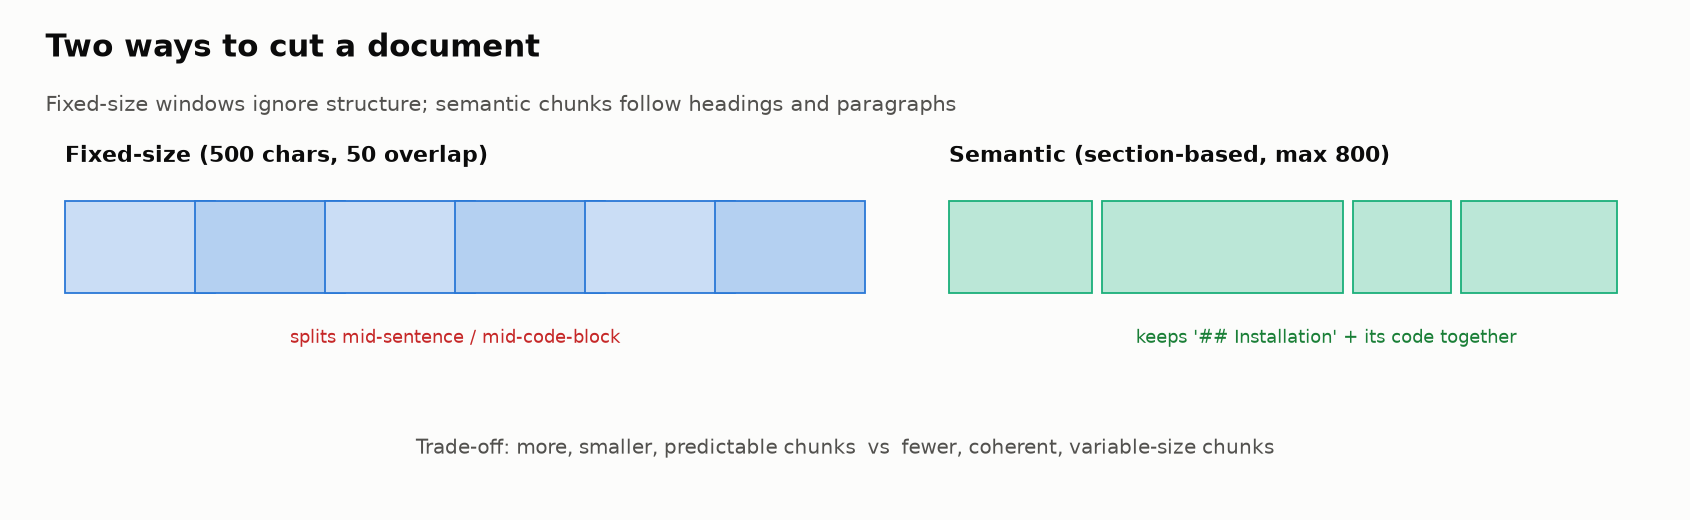

<sub>🖼️ *Fixed-size windows vs. structure-aware semantic chunks*</sub>

In [ ]:
# ============================================================
# CHUNKING STRATEGIES
# ============================================================
# We implement two strategies to compare.
# Each returns a list of chunks with metadata.

from dataclasses import dataclass
from typing import List
import re

@dataclass
class Chunk:
    """A single chunk from a document.
    
    Attributes:
        id: Unique identifier (doc_id + chunk_index)
        content: The actual text content of this chunk
        doc_id: ID of the source document
        doc_title: Title of the source document (useful for citations)
        chunk_index: Position of this chunk within the document
        start_char: Starting character position in original doc
        end_char: Ending character position in original doc
    """
    id: str
    content: str
    doc_id: str
    doc_title: str
    chunk_index: int
    start_char: int
    end_char: int


def fixed_size_chunking(
    documents: List[Dict],
    chunk_size: int = 500,
    overlap: int = 50
) -> List[Chunk]:
    """
    Split documents into fixed-size chunks with overlap.
    
    This is the simplest chunking strategy:
    - Predictable chunk sizes (good for token budget management)
    - Overlap prevents cutting important context
    - May split sentences/paragraphs awkwardly
    
    Args:
        documents: List of document dicts with 'id', 'title', 'content'
        chunk_size: Target size in characters (not tokens)
        overlap: Number of characters to overlap between chunks
    
    Returns:
        List of Chunk objects
    """
    chunks = []
    
    for doc in documents:
        content = doc['content'].strip()
        doc_id = doc['id']
        doc_title = doc['title']
        
        # Slide a window across the content
        start = 0
        chunk_index = 0
        
        while start < len(content):
            # Calculate end position
            end = min(start + chunk_size, len(content))
            
            # Extract chunk content
            chunk_content = content[start:end]
            
            # Create chunk object
            chunks.append(Chunk(
                id=f"{doc_id}_chunk_{chunk_index:03d}",
                content=chunk_content,
                doc_id=doc_id,
                doc_title=doc_title,
                chunk_index=chunk_index,
                start_char=start,
                end_char=end
            ))
            
            # Move to next chunk (with overlap)
            start = end - overlap if end < len(content) else end
            chunk_index += 1
    
    return chunks


def semantic_chunking(
    documents: List[Dict],
    max_chunk_size: int = 800,
    min_chunk_size: int = 100
) -> List[Chunk]:
    """
    Split documents at semantic boundaries (sections, paragraphs).
    
    This strategy respects document structure:
    - Splits at markdown headers (##, ###)
    - Splits at paragraph boundaries
    - Keeps code blocks together
    - Merges tiny chunks with neighbors
    
    Args:
        documents: List of document dicts
        max_chunk_size: Maximum chunk size (will split further if exceeded)
        min_chunk_size: Minimum chunk size (will merge if too small)
    
    Returns:
        List of Chunk objects
    """
    chunks = []
    
    for doc in documents:
        content = doc['content'].strip()
        doc_id = doc['id']
        doc_title = doc['title']
        
        # Split by markdown sections (## or ###)
        # This regex keeps the header with its section
        sections = re.split(r'(?=\n## |\n### )', content)
        
        chunk_index = 0
        current_pos = 0
        
        for section in sections:
            section = section.strip()
            if not section:
                continue
            
            # If section is too large, split by paragraphs
            if len(section) > max_chunk_size:
                paragraphs = section.split('\n\n')
                current_chunk = ""
                
                for para in paragraphs:
                    para = para.strip()
                    if not para:
                        continue
                    
                    # If adding this paragraph would exceed max, save current chunk
                    if len(current_chunk) + len(para) > max_chunk_size and current_chunk:
                        chunks.append(Chunk(
                            id=f"{doc_id}_chunk_{chunk_index:03d}",
                            content=current_chunk,
                            doc_id=doc_id,
                            doc_title=doc_title,
                            chunk_index=chunk_index,
                            start_char=current_pos,
                            end_char=current_pos + len(current_chunk)
                        ))
                        current_pos += len(current_chunk)
                        chunk_index += 1
                        current_chunk = para
                    else:
                        current_chunk = current_chunk + "\n\n" + para if current_chunk else para
                
                # Save remaining chunk
                if current_chunk:
                    chunks.append(Chunk(
                        id=f"{doc_id}_chunk_{chunk_index:03d}",
                        content=current_chunk,
                        doc_id=doc_id,
                        doc_title=doc_title,
                        chunk_index=chunk_index,
                        start_char=current_pos,
                        end_char=current_pos + len(current_chunk)
                    ))
                    current_pos += len(current_chunk)
                    chunk_index += 1
            else:
                # Section fits in one chunk
                chunks.append(Chunk(
                    id=f"{doc_id}_chunk_{chunk_index:03d}",
                    content=section,
                    doc_id=doc_id,
                    doc_title=doc_title,
                    chunk_index=chunk_index,
                    start_char=current_pos,
                    end_char=current_pos + len(section)
                ))
                current_pos += len(section)
                chunk_index += 1
    
    return chunks


# Create chunks using both strategies
fixed_chunks = fixed_size_chunking(DOCUMENTS, chunk_size=500, overlap=50)
semantic_chunks = semantic_chunking(DOCUMENTS, max_chunk_size=800)

print(f"✅ Created chunks using two strategies:")
print(f"   Fixed-size (500 chars): {len(fixed_chunks)} chunks")
print(f"   Semantic: {len(semantic_chunks)} chunks")
print(f"")
print(f"📊 Chunk size statistics:")
print(f"   Fixed: avg={np.mean([len(c.content) for c in fixed_chunks]):.0f}, "
      f"min={min(len(c.content) for c in fixed_chunks)}, "
      f"max={max(len(c.content) for c in fixed_chunks)}")
print(f"   Semantic: avg={np.mean([len(c.content) for c in semantic_chunks]):.0f}, "
      f"min={min(len(c.content) for c in semantic_chunks)}, "
      f"max={max(len(c.content) for c in semantic_chunks)}")

In [ ]:
# Let's examine a few chunks to understand the difference
print("=" * 60)
print("FIXED-SIZE CHUNK EXAMPLE (first chunk from doc-001)")
print("=" * 60)
first_fixed = [c for c in fixed_chunks if c.doc_id == "doc-001"][0]
print(f"ID: {first_fixed.id}")
print(f"Length: {len(first_fixed.content)} chars")
print(f"Content:\n{first_fixed.content[:300]}...")

print("\n" + "=" * 60)
print("SEMANTIC CHUNK EXAMPLE (first chunk from doc-001)")
print("=" * 60)
first_semantic = [c for c in semantic_chunks if c.doc_id == "doc-001"][0]
print(f"ID: {first_semantic.id}")
print(f"Length: {len(first_semantic.content)} chars")
print(f"Content:\n{first_semantic.content[:300]}...")

### 🤔 Think About It

Before running the evaluation, predict:
1. Which chunking strategy will have better **Recall@5**? Why?
2. Which will have better **Precision@5**? Why?
3. For which types of questions might they differ most?

Write your predictions here (we'll check them later):
- My prediction for best Recall@5: _______________
- My prediction for best Precision@5: _______________
- Questions where they differ most: _______________

---

## 🗄️ Task 4: Set Up Weaviate Vector Database

### Goal
Create a Weaviate vector database and store our chunks with embeddings.

### Why Weaviate?
Weaviate is a production-grade vector database that:
- Supports hybrid search (vector + keyword)
- Has built-in reranking
- Scales to billions of vectors
- Can run embedded (in-process) for development

We'll use **embedded mode**: the Python client downloads a Weaviate binary and runs it inside your runtime, so there's no Docker and no account.

> 🧩 **Production pattern: a thin storage adapter.** All database calls go through a tiny `VectorStore` interface (`recreate`, `insert`, `count`, `search`). If embedded Weaviate can't start in your environment (for example, a network that blocks the binary download), the lab automatically falls back to an **in-memory** store with the *same* interface and the *same* cosine math, so every later cell still works. Real teams use adapters like this to swap vector databases without touching evaluation code.

In [ ]:
# ============================================================
# INITIALIZE THE VECTOR STORE (Weaviate embedded, v4 client)
# ============================================================
# Weaviate's v4 client replaced `weaviate.Client(embedded_options=...)` with
# `weaviate.connect_to_embedded()` and a collections-based API. Old tutorials
# that use `client.schema` / `client.query.get(...)` no longer work.

from weaviate.classes.config import Configure, Property, DataType
from weaviate.classes.query import MetadataQuery


class WeaviateStore:
    """Vector store backed by embedded Weaviate (cosine distance, self-provided vectors)."""
    backend = "weaviate-embedded"

    def __init__(self):
        self.client = weaviate.connect_to_embedded(
            environment_variables={"LOG_LEVEL": "error"})   # keep server logs quiet

    def recreate(self, name):
        if self.client.collections.exists(name):
            self.client.collections.delete(name)
        props = [Property(name="content", data_type=DataType.TEXT),
                 Property(name="doc_id", data_type=DataType.TEXT),
                 Property(name="doc_title", data_type=DataType.TEXT),
                 Property(name="chunk_index", data_type=DataType.INT)]
        try:   # newer v4 clients
            self.client.collections.create(name, properties=props,
                                           vector_config=Configure.Vectors.self_provided())
        except (AttributeError, TypeError):   # older v4 clients
            self.client.collections.create(name, properties=props,
                                           vectorizer_config=Configure.Vectorizer.none())

    def insert(self, name, objects, vectors):
        col = self.client.collections.get(name)
        with col.batch.fixed_size(batch_size=100) as batch:
            for obj, vec in zip(objects, vectors):
                batch.add_object(properties=obj, vector=[float(x) for x in vec])
        if col.batch.failed_objects:
            raise RuntimeError(f"{len(col.batch.failed_objects)} objects failed to insert")

    def count(self, name):
        return self.client.collections.get(name).aggregate.over_all(total_count=True).total_count

    def search(self, name, vector, k):
        res = self.client.collections.get(name).query.near_vector(
            near_vector=[float(x) for x in vector], limit=k,
            return_metadata=MetadataQuery(distance=True))
        return [{"id": str(o.uuid), "distance": o.metadata.distance, **o.properties} for o in res.objects]

    def close(self):
        self.client.close()


class InMemoryStore:
    """Fallback with the same interface: brute-force cosine search in numpy."""
    backend = "in-memory (fallback)"

    def __init__(self):
        self.cols = {}

    def recreate(self, name):
        self.cols[name] = {"objects": [], "vectors": np.zeros((0, 0))}

    def insert(self, name, objects, vectors):
        v = np.asarray(vectors, dtype=float)
        v = v / np.linalg.norm(v, axis=1, keepdims=True)
        col = self.cols[name]
        col["objects"] += list(objects)
        col["vectors"] = v if col["vectors"].size == 0 else np.vstack([col["vectors"], v])

    def count(self, name):
        return len(self.cols[name]["objects"])

    def search(self, name, vector, k):
        col = self.cols[name]
        q = np.asarray(vector, dtype=float); q = q / np.linalg.norm(q)
        dist = 1 - col["vectors"] @ q                      # cosine distance, same as Weaviate
        top = np.argsort(dist)[:k]
        return [{"id": f"{name}-{i}", "distance": float(dist[i]), **col["objects"][i]} for i in top]

    def close(self):
        pass


try:
    store = WeaviateStore()
    print(f"✅ Embedded Weaviate is ready: {store.client.is_ready()}")
except Exception as e:
    print(f"⚠️  Embedded Weaviate unavailable ({type(e).__name__}: {str(e)[:120]})")
    print("   Falling back to the in-memory store. Every later cell works the same way.")
    store = InMemoryStore()
print(f"🗄️  Vector store backend: {store.backend}")

In [ ]:
# ============================================================
# CREATE COLLECTIONS
# ============================================================
# Two collections let us compare chunking strategies side by side:
# - FixedChunks:    fixed-size chunking
# - SemanticChunks: semantic chunking
#
# Each object stores: content, doc_id, doc_title, chunk_index.
# We supply our OWN vectors ("self-provided"), so Weaviate does no embedding itself.

for collection_name in ["FixedChunks", "SemanticChunks"]:
    store.recreate(collection_name)   # deletes any previous copy for clean re-runs

print("✅ Created collections: FixedChunks, SemanticChunks")

In [ ]:
# ============================================================
# INITIALIZE EMBEDDING MODEL
# ============================================================
# We use sentence-transformers for local embeddings.
# In production, you might use:
# - OpenAI text-embedding-3-small/large
# - Cohere embed-v3
# - Voyage embeddings
#
# all-MiniLM-L6-v2 is:
# - Fast (for quick iteration)
# - Decent quality (not state-of-the-art)
# - Free and local

# Initialize embedding model
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')
EMBEDDING_DIM = 384  # Dimension of all-MiniLM-L6-v2

def embed_texts(texts: List[str]) -> np.ndarray:
    """
    Generate embeddings for a list of texts.
    
    In production, you'd add:
    - Batching for large lists
    - Caching to avoid re-embedding
    - Error handling for API calls
    
    Args:
        texts: List of strings to embed
    
    Returns:
        numpy array of shape (len(texts), EMBEDDING_DIM)
    """
    return embedding_model.encode(texts, show_progress_bar=True)

print(f"✅ Embedding model loaded: all-MiniLM-L6-v2")
print(f"   Embedding dimension: {EMBEDDING_DIM}")

In [ ]:
# ============================================================
# INGEST CHUNKS INTO THE VECTOR STORE
# ============================================================
# This is the core ingestion pipeline:
# 1. Extract text from chunks
# 2. Generate embeddings (batched by sentence-transformers)
# 3. Store objects + vectors, then verify the count

def ingest_chunks(chunks: List[Chunk], collection_name: str):
    """Embed and store chunks in a collection."""
    print(f"\n📥 Ingesting {len(chunks)} chunks into {collection_name}...")

    # Step 1: Extract content for embedding
    contents = [chunk.content for chunk in chunks]

    # Step 2: Generate embeddings
    print("   Generating embeddings...")
    embeddings = embed_texts(contents)

    # Step 3: Batch insert (vector + properties per object)
    print("   Inserting...")
    objects = [{"content": ch.content, "doc_id": ch.doc_id,
                "doc_title": ch.doc_title, "chunk_index": ch.chunk_index} for ch in chunks]
    store.insert(collection_name, objects, embeddings)

    # Verify ingestion: never assume a batch write succeeded
    actual_count = store.count(collection_name)
    assert actual_count == len(chunks), f"expected {len(chunks)} objects, found {actual_count}"
    print(f"   ✅ Ingested {actual_count} chunks into {collection_name}")

# Ingest both chunk sets
ingest_chunks(fixed_chunks, "FixedChunks")
ingest_chunks(semantic_chunks, "SemanticChunks")

### Checkpoint ✅

You should now have:
- Two collections created (Weaviate, or the in-memory fallback)
- Fixed chunks ingested
- Semantic chunks ingested
- All chunks have embeddings

---

## 🔍 Task 5: Implement Retrieval Pipeline

### Goal
Build a retrieval function that:
1. Embeds the query
2. Searches Weaviate for similar chunks
3. Returns top-K results with scores

> 🚀 Reranking with a cross-encoder is a common next step; it's Exercise 4's stretch idea.

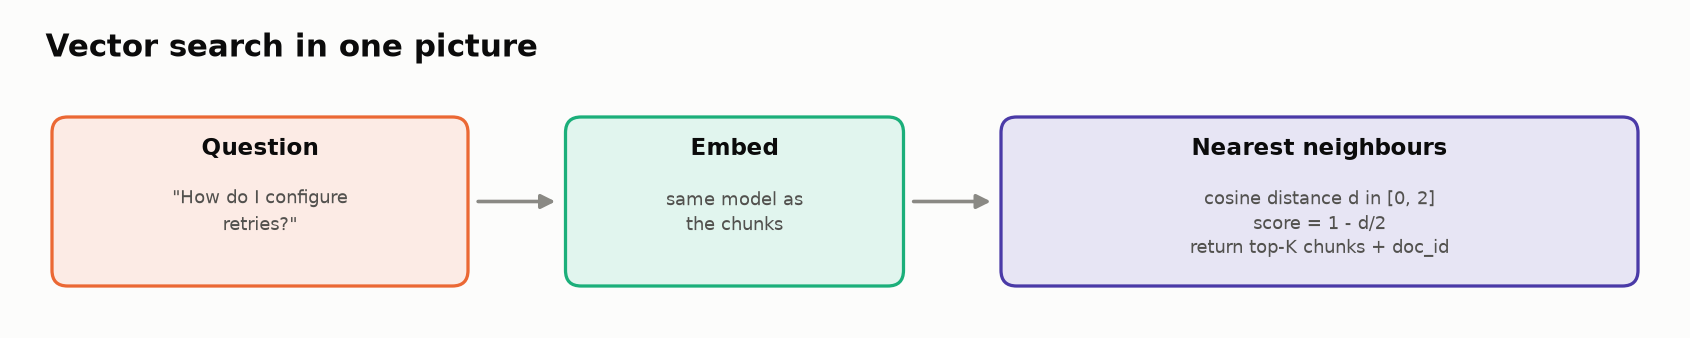

<sub>🖼️ *Retrieval = embed the question with the same model, then nearest-neighbour search*</sub>

In [ ]:
# ============================================================
# RETRIEVAL FUNCTIONS
# ============================================================

@dataclass
class RetrievalResult:
    """A single retrieved chunk with its score.
    
    Attributes:
        chunk_id: The chunk's ID (for tracking)
        content: The text content
        doc_id: Source document ID (for evaluation)
        doc_title: Source document title (for display)
        score: Similarity/relevance score (higher is better)
    """
    chunk_id: str
    content: str
    doc_id: str
    doc_title: str
    score: float


def retrieve(
    query: str,
    collection_name: str,
    top_k: int = 5
) -> List[RetrievalResult]:
    """
    Retrieve top-K chunks for a query.
    
    This implements vector similarity search:
    1. Embed the query using the same model as docs
    2. Find nearest neighbors in Weaviate
    3. Return with similarity scores
    
    Args:
        query: The user's question
        collection_name: Which collection to search
        top_k: Number of results to return
    
    Returns:
        List of RetrievalResult objects, sorted by score (descending)
    """
    # Step 1: Embed the query
    query_embedding = embed_texts([query])[0].tolist()
    
    # Step 2: Nearest-neighbour search in the vector store
    results = store.search(collection_name, query_embedding, top_k)

    # Step 3: Parse results
    retrieval_results = []

    for item in results:
        # Convert distance to similarity score (cosine distance is in [0, 2])
        # Similarity = 1 - (distance / 2), so 0 distance = 1.0 similarity
        distance = item['distance']
        score = 1 - (distance / 2)

        retrieval_results.append(RetrievalResult(
            chunk_id=item['id'],
            content=item['content'],
            doc_id=item['doc_id'],
            doc_title=item['doc_title'],
            score=score
        ))
    
    return retrieval_results


# Test retrieval
test_query = "How do I install DataFlow?"
print(f"Query: {test_query}")
print(f"\n--- Results from FixedChunks ---")
fixed_results = retrieve(test_query, "FixedChunks", top_k=3)
for i, r in enumerate(fixed_results, 1):
    print(f"{i}. [{r.score:.3f}] {r.doc_title} (chunk from {r.doc_id})")
    print(f"   {r.content[:100]}...\n")

print(f"\n--- Results from SemanticChunks ---")
semantic_results = retrieve(test_query, "SemanticChunks", top_k=3)
for i, r in enumerate(semantic_results, 1):
    print(f"{i}. [{r.score:.3f}] {r.doc_title} (chunk from {r.doc_id})")
    print(f"   {r.content[:100]}...\n")

### Checkpoint ✅

You should see:
- Retrieved chunks from both collections
- Similarity scores (higher is more relevant)
- The "install" question should retrieve doc-001 (Getting Started)

---

## 📊 Task 6: Evaluate Retrieval Quality

### Goal
Compute retrieval metrics to compare chunking strategies:
- **Recall@K**: Did we retrieve the relevant documents?
- **Precision@K**: What fraction of retrieved docs are relevant?
- **nDCG@K**: Is the ranking good (relevant docs ranked higher)?

### Why These Metrics?
- **Recall** tells you if you're **missing** relevant information
- **Precision** tells you if you're **drowning in noise**
- **nDCG** tells you if the **order** is right

In [ ]:
# ============================================================
# RETRIEVAL METRICS (computed on the ranked list of retrieved CHUNKS)
# ============================================================
# Each retrieved chunk is "relevant" if it comes from a relevant document.
# Working at chunk level (not de-duplicated documents) is what lets us see
# a difference between chunking strategies: it rewards a top-K list that is
# full of useful evidence, not just one that touches the right document once.

def compute_recall_at_k(
    retrieved_doc_ids: List[str],
    relevant_doc_ids: List[str],
    k: int = 5
) -> float:
    """
    Recall@K: what fraction of the relevant DOCUMENTS appear anywhere in the top K chunks?

    Formula: |docs(top-K) ∩ relevant| / |relevant|
    """
    if not relevant_doc_ids:
        return 1.0  # Nothing to find
    found = set(retrieved_doc_ids[:k]) & set(relevant_doc_ids)
    return len(found) / len(set(relevant_doc_ids))


def compute_precision_at_k(
    retrieved_doc_ids: List[str],
    relevant_doc_ids: List[str],
    k: int = 5
) -> float:
    """
    Precision@K: what fraction of the K retrieved CHUNKS come from a relevant document?

    Formula: (# of top-K chunks whose doc_id is relevant) / K
    """
    relevant = set(relevant_doc_ids)
    return sum(1 for d in retrieved_doc_ids[:k] if d in relevant) / k


def compute_ndcg_at_k(
    retrieved_doc_ids: List[str],
    relevant_doc_ids: List[str],
    k: int = 5,
    n_relevant_available: Optional[int] = None
) -> float:
    """
    nDCG@K: are the relevant chunks ranked near the top?

    DCG  = sum over ranks i (1-based) of rel_i / log2(i + 1)
    IDCG = DCG of the best possible list: as many relevant chunks as exist
           (n_relevant_available), all at the top.
    nDCG = DCG / IDCG, always between 0 and 1.
    """
    relevant = set(relevant_doc_ids)
    dcg = sum(1.0 / np.log2(i + 2) for i, d in enumerate(retrieved_doc_ids[:k]) if d in relevant)
    n_ideal = min(k, n_relevant_available if n_relevant_available is not None else k)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(n_ideal))
    return dcg / idcg if idcg else 0.0


# Sanity checks: you should always test metric code on cases you can do by hand
assert compute_precision_at_k(["a", "b", "a", "c", "d"], ["a"], 5) == 0.4
assert compute_recall_at_k(["a", "b"], ["a", "z"], 5) == 0.5
assert abs(compute_ndcg_at_k(["a", "b"], ["a"], 2, n_relevant_available=1) - 1.0) < 1e-9
assert compute_ndcg_at_k(["b", "a"], ["a"], 2, n_relevant_available=1) < 1.0
print("✅ Retrieval metric functions defined (and sanity-checked)")

In [ ]:
# ============================================================
# EVALUATE BOTH CHUNKING STRATEGIES
# ============================================================
# Which chunk list belongs to which collection (needed for the ideal nDCG)
CHUNKS_BY_COLLECTION = {"FixedChunks": fixed_chunks, "SemanticChunks": semantic_chunks}


def n_relevant_chunks(collection_name: str, relevant_doc_ids: List[str]) -> int:
    """How many chunks in this collection come from a relevant document? (for ideal DCG)"""
    return sum(1 for ch in CHUNKS_BY_COLLECTION[collection_name] if ch.doc_id in relevant_doc_ids)


def evaluate_retrieval(
    collection_name: str,
    evaluation_dataset: List[Dict],
    k: int = 5
) -> pd.DataFrame:
    """
    Evaluate retrieval quality on a dataset.

    Returns a DataFrame with per-question metrics.
    """
    results = []

    for item in evaluation_dataset:
        question = item['question']
        relevant_doc_ids = item['relevant_doc_ids']

        # Retrieve, then map each chunk back to its source document (keep the ranking!)
        retrieved = retrieve(question, collection_name, top_k=k)
        retrieved_doc_ids = [r.doc_id for r in retrieved]

        # Compute metrics
        recall = compute_recall_at_k(retrieved_doc_ids, relevant_doc_ids, k)
        precision = compute_precision_at_k(retrieved_doc_ids, relevant_doc_ids, k)
        ndcg = compute_ndcg_at_k(retrieved_doc_ids, relevant_doc_ids, k,
                                 n_relevant_chunks(collection_name, relevant_doc_ids))

        results.append({
            'question': question[:50] + '...' if len(question) > 50 else question,
            'category': item.get('category', 'unknown'),
            'recall@k': recall,
            'precision@k': precision,
            'ndcg@k': ndcg,
            'retrieved_docs': retrieved_doc_ids,
            'relevant_docs': relevant_doc_ids
        })

    return pd.DataFrame(results)


# Evaluate both strategies
print("Evaluating Fixed-Size Chunking...")
fixed_eval = evaluate_retrieval("FixedChunks", EVALUATION_DATASET, k=5)

print("Evaluating Semantic Chunking...")
semantic_eval = evaluate_retrieval("SemanticChunks", EVALUATION_DATASET, k=5)

print("\n✅ Evaluation complete!")

In [ ]:
# ============================================================
# COMPARE RESULTS
# ============================================================

print("=" * 70)
print("RETRIEVAL EVALUATION RESULTS")
print("=" * 70)

print("\n📊 FIXED-SIZE CHUNKING (500 chars, 50 overlap)")
print("-" * 70)
print(fixed_eval[['question', 'recall@k', 'precision@k', 'ndcg@k']].to_string(index=False))
print(f"\nAVERAGES: Recall@5={fixed_eval['recall@k'].mean():.3f}, "
      f"Precision@5={fixed_eval['precision@k'].mean():.3f}, "
      f"nDCG@5={fixed_eval['ndcg@k'].mean():.3f}")

print("\n📊 SEMANTIC CHUNKING (section-based)")
print("-" * 70)
print(semantic_eval[['question', 'recall@k', 'precision@k', 'ndcg@k']].to_string(index=False))
print(f"\nAVERAGES: Recall@5={semantic_eval['recall@k'].mean():.3f}, "
      f"Precision@5={semantic_eval['precision@k'].mean():.3f}, "
      f"nDCG@5={semantic_eval['ndcg@k'].mean():.3f}")

# Summary comparison
print("\n" + "=" * 70)
print("SUMMARY COMPARISON")
print("=" * 70)
comparison = pd.DataFrame({
    'Metric': ['Recall@5', 'Precision@5', 'nDCG@5'],
    'Fixed-Size': [
        fixed_eval['recall@k'].mean(),
        fixed_eval['precision@k'].mean(),
        fixed_eval['ndcg@k'].mean()
    ],
    'Semantic': [
        semantic_eval['recall@k'].mean(),
        semantic_eval['precision@k'].mean(),
        semantic_eval['ndcg@k'].mean()
    ]
})
comparison['Winner'] = comparison.apply(
    lambda row: 'Semantic' if row['Semantic'] > row['Fixed-Size'] else 
                ('Tie' if row['Semantic'] == row['Fixed-Size'] else 'Fixed-Size'),
    axis=1
)
comparison['Delta'] = (comparison['Semantic'] - comparison['Fixed-Size']).apply(
    lambda x: f"+{x:.3f}" if x > 0 else f"{x:.3f}"
)
print(comparison.to_string(index=False))

In [ ]:
# ── 🎨 Visualize the chunking comparison ──
import matplotlib.pyplot as plt

ax = comparison.set_index("Metric")[["Fixed-Size", "Semantic"]].plot(
    kind="bar", figsize=(7, 3.8), width=0.7, color=["#2a78d6", "#1baf7a"])
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 1.1); ax.set_ylabel("mean score over 10 questions"); ax.set_xlabel("")
ax.set_title("Fixed-size vs semantic chunking", loc="left", fontweight="bold")
ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Checkpoint ✅
With the default settings you should see roughly:

| Metric | Fixed-size | Semantic | Winner |
|---|---|---|---|
| Recall@5 | 1.00 | 1.00 | Tie: both always reach the right document |
| Precision@5 | ≈ 0.48 | ≈ 0.62 | **Semantic**: more of its top-5 chunks are on-topic |
| nDCG@5 | ≈ 0.66 | ≈ 0.64 | Fixed-size, by a hair |

*(Exact decimals can shift slightly between embedding-model versions; the pattern is what matters.)*

> 💡 **Why is recall a tie but precision isn't?** With only 6 documents, finding *a* chunk of the right document is easy, so Recall@5 saturates at 1.0 for both strategies. Precision@5 and nDCG@5 are computed over the **chunks**, so they reward a top-5 that's full of useful evidence. That's where chunking shows up. A metric that never moves can't help you decide; pick metrics that **discriminate** between the options you're comparing.

### 🤔 Analyze Your Results

Look at the comparison above and answer:

1. **Which strategy won overall?** Does this match your prediction?

2. **Where did they differ most?** Look at individual questions.

3. **What's the tradeoff?** Consider:
   - Fixed-size creates more chunks (more to search)
   - Semantic chunks are more coherent but variable size

4. **What would you recommend for production?**

---

## 🤖 Task 7: Implement Generation Pipeline

### Goal
Complete the RAG pipeline by generating answers from retrieved context.

We'll use either:
- OpenAI `gpt-4o-mini` (if an API key is available)
- Simulated responses (for learning the evaluation pipeline without API costs)

In [ ]:
# ============================================================
# GENERATION PIPELINE
# ============================================================

if USE_OPENAI:
    from openai import OpenAI
    openai_client = OpenAI()
    
    def generate_answer(question: str, context: str) -> str:
        """
        Generate an answer using OpenAI gpt-4o-mini.
        
        Args:
            question: User's question
            context: Retrieved context from RAG
        
        Returns:
            Generated answer string
        """
        prompt = f"""You are a helpful documentation assistant. Answer the question based ONLY on the provided context.
If the context doesn't contain enough information, say "I don't have enough information to answer this."

Context:
{context}

Question: {question}

Answer:"""
        
        response = openai_client.chat.completions.create(
            model="gpt-4o-mini",
            messages=[{"role": "user", "content": prompt}],
            temperature=0.1,
            max_tokens=300
        )
        
        return response.choices[0].message.content
    
    print("✅ Using OpenAI gpt-4o-mini for generation")

else:
    # Simulated generator for learning without API costs
    STOP = {"the", "a", "an", "is", "are", "how", "what", "do", "does", "i", "my", "to", "of",
            "and", "or", "in", "on", "for", "with", "can", "dataflow"}

    def generate_answer(question: str, context: str) -> str:
        """
        Simulated (extractive) answer generation.

        Picks the 2 context sentences that share the most content words with the
        question, skipping headers, source tags and code fences. It never invents
        text, so it is (almost) perfectly faithful by construction. Keep that in
        mind when you read the faithfulness scores!
        """
        q_words = {w for w in re.findall(r"[a-z0-9]+", question.lower()) if w not in STOP}
        candidates = []
        for line in context.splitlines():
            line = line.strip(" -*")
            if not line or line.startswith(("[From:", "#", "```", "---")):
                continue
            for sent in re.split(r"(?<=[.!?])\s+", line):
                words = set(re.findall(r"[a-z0-9]+", sent.lower()))
                if len(words) >= 3:
                    candidates.append((len(q_words & words), sent))
        candidates.sort(key=lambda t: -t[0])
        best = [s for _, s in candidates[:2]] or ["I don't have enough information to answer this."]
        return " ".join(best)

    print("⚠️ Using simulated generation (no API key)")
    print("   The evaluation pipeline works identically with real or simulated generation.")

In [ ]:
# ============================================================
# COMPLETE RAG PIPELINE
# ============================================================

@dataclass
class RAGResponse:
    """Complete RAG response with all components."""
    question: str
    answer: str
    retrieved_chunks: List[RetrievalResult]
    context_used: str


def rag_pipeline(
    question: str,
    collection_name: str,
    top_k: int = 5
) -> RAGResponse:
    """
    Execute the full RAG pipeline.
    
    Steps:
    1. Retrieve relevant chunks
    2. Assemble context from chunks
    3. Generate answer using context
    
    Args:
        question: User's question
        collection_name: Which vector collection to use
        top_k: Number of chunks to retrieve
    
    Returns:
        RAGResponse with answer and all intermediate data
    """
    # Step 1: Retrieve
    retrieved = retrieve(question, collection_name, top_k=top_k)
    
    # Step 2: Assemble context
    context_parts = []
    for r in retrieved:
        context_parts.append(f"[From: {r.doc_title}]\n{r.content}")
    context = "\n\n---\n\n".join(context_parts)
    
    # Step 3: Generate
    answer = generate_answer(question, context)
    
    return RAGResponse(
        question=question,
        answer=answer,
        retrieved_chunks=retrieved,
        context_used=context
    )


# Test the complete pipeline
test_question = "How do I configure retry behavior for my tasks?"
response = rag_pipeline(test_question, "SemanticChunks", top_k=3)

print(f"Question: {test_question}")
print(f"\nRetrieved from:")
for r in response.retrieved_chunks:
    print(f"  - {r.doc_title} (score: {r.score:.3f})")
print(f"\nAnswer:\n{response.answer}")

---

## 📈 Task 8: Evaluate Generation Quality (RAGAS-style metrics)

### Goal
Evaluate the quality of generated answers using RAGAS metrics:
- **Faithfulness**: Is the answer grounded in the context?
- **Answer Relevancy**: Does the answer address the question?

> ℹ️ This task implements **simplified, offline versions** of two RAGAS metrics. The real `ragas` library uses an LLM to extract and verify claims; the formulas below are word-overlap proxies so you can see the mechanics without an API key.

> ⚠️ **Read the faithfulness scores with suspicion.** Without an API key the generator is *extractive*: it copies sentences from the context, so it's faithful almost by construction (≈ 0.98). High faithfulness here says more about the generator's design than about its quality. With a real LLM, this is the metric that drops.

### Why RAGAS?
RAGAS is the industry-standard framework for RAG evaluation. It provides:
- Well-tested prompts for LLM-as-judge evaluation
- Normalized scores (0-1)
- Correlation with human judgments

In [ ]:
# ============================================================
# GENERATION QUALITY METRICS
# ============================================================
# We implement simplified versions of RAGAS metrics.
# In production, use the full ragas library.

def evaluate_faithfulness(
    answer: str,
    context: str
) -> float:
    """
    Evaluate if the answer is grounded in the context.
    
    Simplified approach:
    - Extract key phrases from answer
    - Check if they appear in context
    - Higher coverage = higher faithfulness
    
    In production, use RAGAS faithfulness which:
    - Extracts claims using LLM
    - Verifies each claim against context
    
    Args:
        answer: Generated answer
        context: Retrieved context
    
    Returns:
        Faithfulness score 0-1
    """
    # Simple n-gram overlap as proxy for faithfulness
    answer_words = set(answer.lower().split())
    context_words = set(context.lower().split())
    
    # Remove common words
    stop_words = {'the', 'a', 'an', 'is', 'are', 'was', 'were', 'be', 'been',
                  'to', 'of', 'and', 'or', 'in', 'on', 'at', 'for', 'with',
                  'that', 'this', 'it', 'you', 'can', 'will', 'your'}
    
    answer_words = answer_words - stop_words
    context_words = context_words - stop_words
    
    if not answer_words:
        return 1.0
    
    overlap = answer_words & context_words
    faithfulness = len(overlap) / len(answer_words)
    
    return min(faithfulness, 1.0)


def evaluate_answer_relevancy(
    question: str,
    answer: str
) -> float:
    """
    Evaluate if the answer is relevant to the question.
    
    Simplified approach:
    - Check overlap between question and answer terms
    - Penalize very short or "I don't know" answers
    
    In production, use RAGAS answer_relevancy which:
    - Generates questions from the answer
    - Measures similarity to original question
    
    Args:
        question: Original question
        answer: Generated answer
    
    Returns:
        Relevancy score 0-1
    """
    # Check for refusal/uncertainty
    refusal_phrases = ["don't have", "cannot", "no information", "not sure"]
    answer_lower = answer.lower()
    
    if any(phrase in answer_lower for phrase in refusal_phrases):
        return 0.3  # Refusal is somewhat relevant (honest)
    
    # Very short answers are likely low relevancy
    if len(answer.split()) < 5:
        return 0.4
    
    # Check term overlap
    question_words = set(question.lower().split())
    answer_words = set(answer.lower().split())
    
    stop_words = {'the', 'a', 'an', 'is', 'are', 'how', 'what', 'do', 'does',
                  'to', 'of', 'and', 'or', 'in', 'on', 'at', 'for', 'with', 'i', 'my'}
    
    question_words = question_words - stop_words
    answer_words = answer_words - stop_words
    
    if not question_words:
        return 0.5
    
    overlap = question_words & answer_words
    relevancy = len(overlap) / len(question_words)
    
    # Scale to reasonable range
    return min(0.5 + relevancy * 0.5, 1.0)


print("✅ Generation evaluation functions defined")

In [ ]:
# ============================================================
# FULL RAG EVALUATION
# ============================================================
# Run the complete pipeline on evaluation set and measure everything.

def evaluate_rag_pipeline(
    collection_name: str,
    evaluation_dataset: List[Dict],
    top_k: int = 5
) -> pd.DataFrame:
    """
    Run full RAG evaluation: retrieval + generation.
    
    Args:
        collection_name: Vector collection to use
        evaluation_dataset: Evaluation questions with ground truth
        top_k: Number of chunks to retrieve
    
    Returns:
        DataFrame with all metrics per question
    """
    results = []
    
    for i, item in enumerate(evaluation_dataset):
        print(f"  Processing question {i+1}/{len(evaluation_dataset)}...", end="\r")
        
        question = item['question']
        relevant_doc_ids = item['relevant_doc_ids']
        
        # Run RAG pipeline
        response = rag_pipeline(question, collection_name, top_k=top_k)
        
        # Get retrieved doc IDs
        retrieved_doc_ids = [r.doc_id for r in response.retrieved_chunks]
        
        # Compute retrieval metrics
        recall = compute_recall_at_k(retrieved_doc_ids, relevant_doc_ids, top_k)
        precision = compute_precision_at_k(retrieved_doc_ids, relevant_doc_ids, top_k)
        ndcg = compute_ndcg_at_k(retrieved_doc_ids, relevant_doc_ids, top_k,
                                 n_relevant_chunks(collection_name, relevant_doc_ids))
        
        # Compute generation metrics
        faithfulness = evaluate_faithfulness(response.answer, response.context_used)
        relevancy = evaluate_answer_relevancy(question, response.answer)
        
        results.append({
            'question': question[:40] + '...',
            'category': item.get('category', 'unknown'),
            # Retrieval metrics
            'recall@k': recall,
            'precision@k': precision,
            'ndcg@k': ndcg,
            # Generation metrics
            'faithfulness': faithfulness,
            'relevancy': relevancy,
            # Metadata
            'answer_length': len(response.answer.split()),
            'answer': response.answer[:100] + '...' if len(response.answer) > 100 else response.answer
        })
    
    print("                                        ")  # Clear progress line
    return pd.DataFrame(results)


# Run evaluation on semantic chunks (the better strategy)
print("Running full RAG evaluation on SemanticChunks...")
full_eval = evaluate_rag_pipeline("SemanticChunks", EVALUATION_DATASET, top_k=5)
print("✅ Evaluation complete!")

In [ ]:
# ============================================================
# DISPLAY RESULTS
# ============================================================

print("=" * 80)
print("FULL RAG EVALUATION RESULTS")
print("=" * 80)

# Show per-question results
print("\n📊 Per-Question Metrics:")
display_cols = ['question', 'recall@k', 'precision@k', 'faithfulness', 'relevancy']
print(full_eval[display_cols].to_string(index=False))

# Show aggregates
print("\n" + "=" * 80)
print("AGGREGATE METRICS")
print("=" * 80)

metrics_summary = {
    'Metric': ['Recall@5', 'Precision@5', 'nDCG@5', 'Faithfulness', 'Answer Relevancy'],
    'Mean': [
        full_eval['recall@k'].mean(),
        full_eval['precision@k'].mean(),
        full_eval['ndcg@k'].mean(),
        full_eval['faithfulness'].mean(),
        full_eval['relevancy'].mean()
    ],
    'Min': [
        full_eval['recall@k'].min(),
        full_eval['precision@k'].min(),
        full_eval['ndcg@k'].min(),
        full_eval['faithfulness'].min(),
        full_eval['relevancy'].min()
    ],
    'Max': [
        full_eval['recall@k'].max(),
        full_eval['precision@k'].max(),
        full_eval['ndcg@k'].max(),
        full_eval['faithfulness'].max(),
        full_eval['relevancy'].max()
    ]
}

summary_df = pd.DataFrame(metrics_summary)
print(summary_df.to_string(index=False, float_format='%.3f'))

---

## 🎯 Task 9: Production Readiness Assessment

### Goal
Make a deployment recommendation based on evaluation results.

### Checkpoint ✅ (after you run the next cell)
On the semantic collection you should see **recall, precision and faithfulness above target**, **answer relevancy ≈ 0.70 (meets minimum, below target)**, and an overall verdict of **CONDITIONAL**. Ask yourself: is relevancy low because the *answers* are off-topic, or because a word-overlap metric is a crude proxy for relevancy?

### Production Thresholds (Example)

| Metric | Minimum | Target | Your Result |
|--------|---------|--------|-------------|
| Recall@5 | 0.70 | 0.85 | ? |
| Precision@5 | 0.25 | 0.40 | ? |
| Faithfulness | 0.75 | 0.90 | ? |
| Relevancy | 0.65 | 0.80 | ? |

> 💡 Thresholds are a **product decision**, not a law of nature: a medical assistant needs far stricter faithfulness than an internal docs bot. Write them down *before* you look at results so you can't move the goalposts.

In [ ]:
# ============================================================
# PRODUCTION READINESS CHECK
# ============================================================

# Define thresholds
THRESHOLDS = {
    'recall@k': {'min': 0.70, 'target': 0.85},
    'precision@k': {'min': 0.25, 'target': 0.40},
    'faithfulness': {'min': 0.75, 'target': 0.90},
    'relevancy': {'min': 0.65, 'target': 0.80},
}

def assess_readiness(eval_df: pd.DataFrame, thresholds: dict) -> dict:
    """
    Assess production readiness against thresholds.
    
    Returns:
        Assessment dict with pass/fail status and details
    """
    assessment = {
        'overall': 'PASS',
        'metrics': {},
        'warnings': [],
        'blockers': []
    }
    
    for metric, bounds in thresholds.items():
        value = eval_df[metric].mean()
        
        if value >= bounds['target']:
            status = '✅ EXCEEDS TARGET'
        elif value >= bounds['min']:
            status = '⚠️ MEETS MINIMUM'
            assessment['warnings'].append(f"{metric}: {value:.3f} (target: {bounds['target']})")
        else:
            status = '❌ BELOW MINIMUM'
            assessment['blockers'].append(f"{metric}: {value:.3f} (min: {bounds['min']})")
            assessment['overall'] = 'FAIL'
        
        assessment['metrics'][metric] = {
            'value': value,
            'min': bounds['min'],
            'target': bounds['target'],
            'status': status
        }
    
    if assessment['warnings'] and not assessment['blockers']:
        assessment['overall'] = 'CONDITIONAL'
    
    return assessment


# Run assessment
readiness = assess_readiness(full_eval, THRESHOLDS)

print("=" * 80)
print("PRODUCTION READINESS ASSESSMENT")
print("=" * 80)

for metric, details in readiness['metrics'].items():
    print(f"\n{metric}:")
    print(f"  Value: {details['value']:.3f}")
    print(f"  Range: [{details['min']:.2f} minimum, {details['target']:.2f} target]")
    print(f"  Status: {details['status']}")

print("\n" + "=" * 80)
print(f"OVERALL: {readiness['overall']}")
print("=" * 80)

if readiness['blockers']:
    print("\n❌ BLOCKERS (must fix before production):")
    for blocker in readiness['blockers']:
        print(f"  - {blocker}")

if readiness['warnings']:
    print("\n⚠️ WARNINGS (should improve):")
    for warning in readiness['warnings']:
        print(f"  - {warning}")

---

## 🛠️ Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `TypeError: Client.__init__() got an unexpected keyword argument 'embedded_options'` | Code written for the **v3** Weaviate client | This notebook uses v4 (`weaviate.connect_to_embedded()`). Re-run from the top |
| `⚠️ Embedded Weaviate unavailable ...` | Binary download blocked, or an old embedded process still holds the port | The lab continues on the in-memory fallback. To retry Weaviate: Runtime → Restart session, run from the top |
| `WeaviateStartUpError` on the second run | A previous embedded instance is still running | Run the **Clean up** cell (or restart the runtime) before re-running Task 4 |
| `NameError: name 'store' is not defined` | Task 4's first cell was skipped | Run cells in order from the top |
| All retrieval metrics are 0 | Chunks weren't ingested | Re-run the ingest cell and check the count assertion |
| Weaviate deprecation warnings | Newer client, older call style | Safe to ignore; the adapter supports both |


---

## 🏁 Key Takeaways

### What You Built
1. **Complete RAG pipeline** with a Weaviate (v4, embedded) vector store behind a swappable adapter
2. **Two chunking strategies** (fixed vs. semantic) with comparison
3. **Retrieval evaluation** with Recall@K, Precision@K, nDCG
4. **Generation evaluation** with Faithfulness and Relevancy
5. **Production readiness assessment** with clear thresholds

### Key Insights

1. **Chunking matters more than you think**
   - Chunking strategy affects retrieval quality significantly
   - Test multiple strategies on YOUR data

2. **Evaluate retrieval AND generation separately**
   - Good retrieval doesn't guarantee good generation
   - Bad retrieval usually means bad generation

3. **Faithfulness is critical**
   - Users tolerate incomplete answers
   - Users don't tolerate hallucinated answers

4. **Build evaluation into your pipeline from day one**
   - Evaluation datasets should grow with production queries
   - Automate evaluation in CI/CD

### Production Next Steps

If deploying this system to production:

1. **Add observability**: wrap retrieval and generation in Langfuse spans exactly as in Lab 01 (`retriever` + `generation` observations)
2. **Implement reranking** for better precision
3. **Create larger evaluation sets** from real user queries
4. **Add safety checks** (content filtering, PII detection)
5. **Set up continuous monitoring** with alerting
6. **A/B test** chunking strategies with real users

In [ ]:
# Clean up: stop embedded Weaviate (a no-op for the in-memory fallback)
store.close()
print("✅ Lab complete! Vector store closed.")

---

## 🏋️ Exercises

Practice production RAG evaluation: faithfulness, retrieval quality, and end-to-end scoring.

### Exercise 1 — Beginner: Context hit rate
Fraction of questions where the ground-truth doc appears in retrieved context.

<details>
<summary>Show solution</summary>

```python
def hit_rate(cases):
    return sum(c["gt_doc"] in c["retrieved"] for c in cases) / len(cases)
print(hit_rate([{"gt_doc":"d1","retrieved":["d1","d2"]}]))
```
</details>

### Exercise 2 — Applied: Faithfulness flag
Flag answers containing claims not present in context (simple overlap heuristic).

<details>
<summary>Show solution</summary>

```python
def unfaithful(answer, context, min_overlap=2):
    ctx = set(context.lower().split())
    return not any(len(set(s.lower().split()) & ctx) >= min_overlap for s in answer.split("."))
print(unfaithful("Limit is 50 MB.", "max upload 50 MB"))
```
</details>

### Exercise 3 — Challenge: Aggregate RAG scorecard
Average per-question precision, faithfulness, and answer-correctness into one report dict.

<details>
<summary>Show solution</summary>

```python
import statistics as st
def scorecard(rows):  # rows: list of dicts with metric keys
    keys = rows[0].keys()
    return {k: round(st.mean(r[k] for r in rows), 2) for k in keys}
print(scorecard([{"prec":1.0,"faith":0.8},{"prec":0.5,"faith":1.0}]))
```
</details>

### Exercise 4 — Stretch: Swap the retriever
Replace the vector retriever with BM25/keyword search, or add a cross-encoder reranker (`CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")`) over the top-10 results, and compare precision + nDCG. (Open-ended.)
